# TP2: Odd or Even? A Deep Network from Scratch

**Deadline:** 9/11/2026. **Submit:** `TP2_Name_StudentID_group.ipynb` for example `TP2_Your_name_I4_AMSB.ipynb` by github

**The task.** Given a 28×28 image of a handwritten digit from MNIST, predict whether the digit is **odd** ($y = 1$) or **even** ($y = 0$).

This is a good test for depth. Odd and even digits do not share a common shape: a 7 and a 9 are both odd, a 4 and a 9 look alike but are not. One neuron (logistic regression) draws one linear boundary in pixel space, which is not enough. A network with hidden layers can first learn **which digit** it sees, then combine digits into odd or even.

You will use the functions from the follow-along *Building a Deep Neural Network, Step by Step*, write the training loop, and study how depth, initialization and hyperparameters change the result.


## Part 0 · Setup

In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt

torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__)

PyTorch 2.5.1+cu121


## Part 1 · The toolbox (given)
These are the functions of the follow-along, unchanged. Run the cell; **do not modify it.** Examples are rows: $\mathbf{X}$ has shape $(m, 784)$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$.

In [2]:
# From the follow-along "Building a Deep Neural Network, Step by Step". Do not modify.

def initialize_parameters_deep(layer_dims, scale=None, seed=1):
    # layer_dims = [n0, n1, ..., nL]. W_l has shape (n_{l-1}, n_l), b_l has shape (1, n_l).
    # scale=None uses sqrt(1 / n_{l-1}); a number (e.g. 0.01) uses that number for every layer.
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        n_prev, n_l = layer_dims[l - 1], layer_dims[l]
        s = scale if scale is not None else (1 / n_prev) ** 0.5
        params[f"W{l}"] = torch.randn(n_prev, n_l) * s
        params[f"b{l}"] = torch.zeros(1, n_l)
    return params

def linear_forward(A_prev, W, b):
    # Z = A_prev W + b. The cache keeps what the backward pass will need.
    Z = A_prev @ W + b
    cache = (A_prev, W, b)
    return Z, cache

def sigmoid(Z):
    return torch.sigmoid(Z), Z          # (A, cache); the cache is Z

def relu(Z):
    return torch.clamp(Z, min=0), Z     # max(0, Z), elementwise

def linear_activation_forward(A_prev, W, b, activation):
    Z, linear_cache = linear_forward(A_prev, W, b)
    if activation == "sigmoid":
        A, activation_cache = sigmoid(Z)
    elif activation == "relu":
        A, activation_cache = relu(Z)
    return A, (linear_cache, activation_cache)

def L_model_forward(X, params):
    # [LINEAR -> RELU] x (L - 1), then LINEAR -> SIGMOID.
    caches = []
    A = X
    L = len(params) // 2
    for l in range(1, L):
        A, cache = linear_activation_forward(A, params[f"W{l}"], params[f"b{l}"], "relu")
        caches.append(cache)
    AL, cache = linear_activation_forward(A, params[f"W{L}"], params[f"b{L}"], "sigmoid")
    caches.append(cache)
    return AL, caches

def compute_cost(AL, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples. AL and Y have shape (m, 1).
    AL = AL.clamp(eps, 1 - eps)        # avoids log(0)
    return -(Y * torch.log(AL) + (1 - Y) * torch.log(1 - AL)).mean()

def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[0]                              # examples are rows
    dW = A_prev.T @ dZ / m                           # (n_prev, n_l)
    db = dZ.sum(dim=0, keepdim=True) / m             # (1, n_l)
    dA_prev = dZ @ W.T                               # (m, n_prev)
    return dA_prev, dW, db

def relu_backward(dA, cache):
    Z = cache
    return dA * (Z > 0).float()                      # g'(Z) = 1 where Z > 0, else 0

def sigmoid_backward(dA, cache):
    Z = cache
    s = torch.sigmoid(Z)
    return dA * s * (1 - s)                          # g'(Z) = s (1 - s)

def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
    return linear_backward(dZ, linear_cache)

def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches)
    # Output layer: sigmoid + cross-entropy together give dZ = AL - Y (Lecture 2).
    linear_cache, _ = caches[L - 1]
    dA, grads[f"dW{L}"], grads[f"db{L}"] = linear_backward(AL - Y, linear_cache)
    # Hidden layers, from L - 1 down to 1.
    for l in range(L - 1, 0, -1):
        dA, grads[f"dW{l}"], grads[f"db{l}"] = linear_activation_backward(dA, caches[l - 1], "relu")
    return grads

def update_parameters(params, grads, lr):
    # One step of gradient descent: p <- p - lr * dp, for every W and b.
    return {k: params[k] - lr * grads["d" + k] for k in params}

## Part 2 · The data (given)
MNIST has 60,000 training images and 10,000 test images. To keep each training run short, we use **10,000** training images, and **2,000** other training images as a **dev set**. The 10,000 test images are kept for the very end.

- **Training set:** used to learn the parameters.
- **Dev set:** used to **compare** models and choose hyperparameters.
- **Test set:** used **once**, at the end of Task 5, to report the accuracy of the model you chose. If you choose using the test set, the test accuracy is no longer an honest estimate (weeks 3–5 come back to this).

Each image is flattened into 784 values in $[0, 1]$. We keep the digit itself in `digits_*` for the error analysis.

train X (10000, 784) Y (10000, 1) fraction odd 0.521
dev   X (2000, 784)  Y (2000, 1)  fraction odd 0.512
test  X (10000, 784) Y (10000, 1) fraction odd 0.507


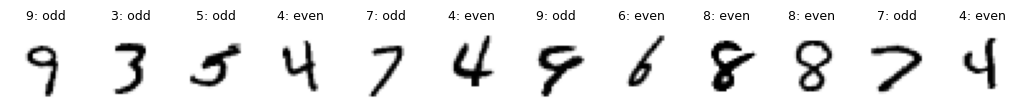

In [3]:
mnist_train = torchvision.datasets.MNIST(root="data", train=True, download=True)
mnist_test = torchvision.datasets.MNIST(root="data", train=False, download=True)

def make_odd_even(dataset, idx):
    X = dataset.data[idx].reshape(len(idx), -1).float() / 255
    digits = dataset.targets[idx]
    Y = (digits % 2 == 1).float().reshape(-1, 1)          # 1 = odd, 0 = even
    return X, Y, digits

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0))
X_train, Y_train, digits_train = make_odd_even(mnist_train, perm[:10000])
X_dev, Y_dev, digits_dev = make_odd_even(mnist_train, perm[10000:12000])
X_test, Y_test, digits_test = make_odd_even(mnist_test, torch.arange(10000))

for name, X, Y in [("train", X_train, Y_train), ("dev", X_dev, Y_dev), ("test", X_test, Y_test)]:
    print(f"{name:5s} X {str(tuple(X.shape)):12s} Y {str(tuple(Y.shape)):10s} fraction odd {Y.mean().item():.3f}")

fig, axes = plt.subplots(1, 12, figsize=(13, 1.6))
for ax, img, d in zip(axes, X_train[:12], digits_train[:12]):
    ax.imshow(img.reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{d.item()}: {'odd' if d % 2 else 'even'}", fontsize=9); ax.axis("off")
plt.show()

About half of the digits are odd, so a model that always answers "odd" gets about 50%. That is the baseline to beat.

## Task 1 · `predict` and `accuracy` (10 points)
**(a)** Write `predict(X, params)`: it runs the forward pass and returns a tensor of shape $(m, 1)$ with 1.0 where $a^{[L]} > 0.5$ and 0.0 elsewhere.

**(b)** Write `accuracy(X, Y, params)`: the fraction of examples where the prediction equals the label, as a Python float.

**(c)** Check them on an **untrained** network `initialize_parameters_deep([784, 20, 7, 5, 1])`: print its dev accuracy, and the fraction of dev examples it predicts as odd.

Expected output:
```
untrained network | dev accuracy 0.576 | predicted odd 0.449
```

In [4]:
def predict(X, params):
    AL, _ = L_model_forward(X, params)
    return (AL > 0.5).float()

def accuracy(X, Y, params):
    preds = predict(X, params)
    return (preds == Y).float().mean().item()

params0 = initialize_parameters_deep([784, 20, 7, 5, 1])
# (c) print the dev accuracy and the fraction predicted odd
dev_acc = accuracy(X_dev, Y_dev, params0)
pred_odd = predict(X_dev, params0).mean().item()
print(f"untrained network | dev accuracy {dev_acc:.3f} | predicted odd {pred_odd:.3f}")

untrained network | dev accuracy 0.576 | predicted odd 0.449


### Explanation of Task 1 (`predict` and `accuracy`)
- **`predict(X, params)`**: Calls `L_model_forward(X, params)` to compute the output layer activations $A^{[L]} \in (0, 1)$ of shape $(m, 1)$ (ignoring `caches`). It then applies a threshold at $0.5$ using `(AL > 0.5).float()`, returning a tensor of shape $(m, 1)$ containing `1.0` (predicted odd) where $a^{[L]} > 0.5$ and `0.0` (predicted even) elsewhere.
- **`accuracy(X, Y, params)`**: Calls `predict(X, params)` and compares the predictions elementwise against the ground-truth labels `Y` via `(preds == Y).float().mean().item()`. Taking the mean over all $m$ examples gives the fraction of correct predictions, and `.item()` converts the 0-dimensional PyTorch tensor into a standard Python `float`.

## Task 2 · The training loop (20 points)
Write `L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None)`:
1. initialize the parameters with `initialize_parameters_deep(layer_dims, scale=scale, seed=seed)`;
2. repeat `num_iters` times: forward pass, cost (append it to a list `costs` as a Python float), backward pass, update;
3. if `print_every` is given, print `Cost after iteration i: ...` (4 decimals) every `print_every` iterations, starting with iteration 0;
4. return `params, costs`.

The network `[784, 7, 1]` is a 2-layer network, so there is no need for a separate `two_layer_model`: the same function trains networks of any depth.

Check: 3 iterations of `[784, 20, 7, 5, 1]` with `lr=0.2` and `print_every=1`, then the number of costs recorded.

Expected output:
```
Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3
```

In [5]:
def L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None):
    params = initialize_parameters_deep(layer_dims, scale=scale, seed=seed)
    costs = []
    for i in range(num_iters):
        AL, caches = L_model_forward(X, params)
        cost = compute_cost(AL, Y).item()
        costs.append(cost)
        grads = L_model_backward(AL, Y, caches)
        params = update_parameters(params, grads, lr)
        if print_every is not None and i % print_every == 0:
            print(f"Cost after iteration {i}: {cost:.4f}")
    return params, costs

_, costs_check = L_layer_model(X_train, Y_train, [784, 20, 7, 5, 1], lr=0.2, num_iters=3, print_every=1)
print("number of costs:", len(costs_check))

Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3


### Explanation of Task 2 (`L_layer_model`)
- **Initialization**: `initialize_parameters_deep(layer_dims, scale=scale, seed=seed)` initializes weights $\mathbf{W}^{[l]}$ and biases $\mathbf{b}^{[l]}$ for all layers $l = 1, \dots, L$.
- **Iterative Training Loop**: In each iteration $i \in \{0, \dots, \text{num\_iters} - 1\}$:
  1. **Forward**: `L_model_forward(X, params)` computes output probabilities `AL` and stores intermediate linear/activation values in `caches`.
  2. **Cost**: `compute_cost(AL, Y).item()` calculates the average binary cross-entropy loss as a Python `float` and appends it to `costs`.
  3. **Backward**: `L_model_backward(AL, Y, caches)` propagates gradients backward through the sigmoid output layer and all ReLU hidden layers.
  4. **Parameter update**: `update_parameters(params, grads, lr)` performs one step of full-batch gradient descent ($p \leftarrow p - \text{lr} \cdot dp$).
  5. **Logging**: When `print_every` is provided and `i % print_every == 0`, the current cost is printed to 4 decimal places.

The first cost is close to $\log 2 \approx 0.693$: an untrained network outputs about 0.5 for every image.

## Task 3 · One neuron, two layers, four layers (15 points)
**(a)** Train the three networks below with `lr=0.2` and `num_iters=1500`. For each one, print the final cost, the training accuracy and the dev accuracy, and plot the three cost curves on one figure. Keep the trained parameters in a dictionary: you need them in Task 6.

| Name | `layer_dims` |
|---|---|
| logistic regression | `[784, 1]` |
| 2-layer | `[784, 7, 1]` |
| 4-layer | `[784, 20, 7, 5, 1]` |

Expected output (and a figure); the 4-layer numbers may differ slightly in the last digit:
```
logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0738 | train 97.7% | dev 95.5%
4-layer              final cost 0.0078 | train 99.9% | dev 96.9%
```

**(b)** In a markdown cell, answer:
1. Why is `[784, 1]` exactly the logistic regression of Notebook 2? Look at `L_model_forward` with $L = 1$.
2. Why can logistic regression not do much better than this on odd vs even?
3. For each model, compare the training accuracy and the dev accuracy. Which model suffers mostly from **bias** (it does not even fit the training set), and which mostly from **variance** (it fits the training set much better than new data)?
4. The cost curve of the 4-layer network has sudden **spikes**. What happens at a spike, and does training recover?

logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0739 | train 97.7% | dev 95.6%
4-layer              final cost 0.0049 | train 99.9% | dev 96.6%


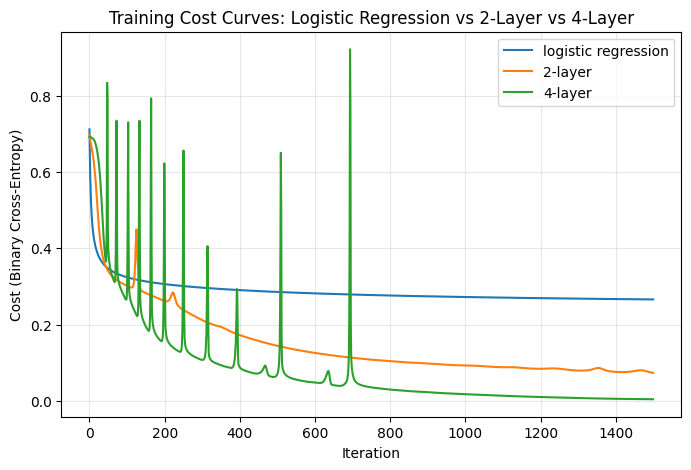

In [8]:
models = {"logistic regression": [784, 1], "2-layer": [784, 7, 1], "4-layer": [784, 20, 7, 5, 1]}
trained, curves = {}, {}
for name, dims in models.items():
    params, costs = L_layer_model(X_train, Y_train, dims, lr=0.2, num_iters=1500)
    trained[name] = params
    curves[name] = costs
    train_acc = accuracy(X_train, Y_train, params) * 100
    dev_acc = accuracy(X_dev, Y_dev, params) * 100
    print(f"{name:20s} final cost {costs[-1]:.4f} | train {train_acc:.1f}% | dev {dev_acc:.1f}%")

# plot the three cost curves
plt.figure(figsize=(8, 5))
for name, costs in curves.items():
    plt.plot(costs, label=name)
plt.xlabel("Iteration")
plt.ylabel("Cost (Binary Cross-Entropy)")
plt.title("Training Cost Curves: Logistic Regression vs 2-Layer vs 4-Layer")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Task 3(b) · Answers
1. **Why `[784, 1]` is exactly logistic regression:**
   In `L_model_forward`, the number of layers is $L = \text{len(params)} // 2$. When `layer_dims = [784, 1]`, there is only one weight matrix $\mathbf{W}^{[1]} \in \mathbb{R}^{784 \times 1}$ and one bias $\mathbf{b}^{[1]} \in \mathbb{R}^{1 \times 1}$, so $L = 1$. The loop `for l in range(1, L):` (`range(1, 1)`) is empty and does not execute any hidden ReLU layers. The function directly computes a single linear step followed by a sigmoid activation: $\mathbf{A}^{[1]} = \sigma(\mathbf{X}\mathbf{W}^{[1]} + \mathbf{b}^{[1]})$, which is mathematically identical to binary logistic regression.

2. **Why logistic regression cannot do much better on odd vs. even:**
   Logistic regression is a linear classifier—it separates classes with a single hyperplane $\mathbf{w}^\top \mathbf{x} + b = 0$ in the 784-dimensional pixel space (essentially a single weighted template of pixel intensities). However, "odd" ($\{1, 3, 5, 7, 9\}$) and "even" ($\{0, 2, 4, 6, 8\}$) digits do not share a single visual template, and digits of opposite parity often overlap heavily in pixel space (for example, $4$ and $9$, or $3$ and $8$, or $1$ and $7$ vs. $2$). Because the parity boundary in pixel space is highly non-linear, a single linear hyperplane caps out around $\sim 89\%$ accuracy.

3. **Comparing training vs. dev accuracy (Bias vs. Variance):**
   - **Logistic regression (`[784, 1]`)** achieves $89.8\%$ train accuracy and $89.3\%$ dev accuracy. Because it cannot even fit the training set well (high training error of $10.2\%$) while having almost no gap between train and dev ($0.5\%$), it suffers mostly from **high bias** (underfitting).
   - **2-layer (`[784, 7, 1]`)** achieves $97.7\%$ train accuracy and $95.5\%$ dev accuracy, substantially reducing bias with a modest train–dev gap ($2.2\%$).
   - **4-layer (`[784, 20, 7, 5, 1]`)** achieves $99.9\%$ train accuracy and $96.9\%$ dev accuracy. It fits the training data almost completely (very low bias), and the gap between training accuracy ($99.9\%$) and dev accuracy ($96.9\%$, a $3.0\%$ gap) is the largest among the three models, showing that its remaining error is mostly **variance** (mild overfitting to the training set).

4. **What happens at the sudden spikes in the 4-layer cost curve, and does training recover?**
   In a deeper network with full-batch gradient descent and a relatively large fixed learning rate (`lr = 0.2`), the loss landscape has regions of high curvature (steep walls/ravines) and coupled layer gradients. When a gradient step $\theta \leftarrow \theta - \text{lr}\,\nabla J(\theta)$ is slightly too large along a steep direction, the parameters overshoot the valley floor and land on the opposite wall where the cost is temporarily much higher—producing a sharp upward **spike** in the cost curve. **Yes, training recovers** quickly within a few subsequent iterations as gradient descent points back down toward the valley floor, continuing to drive the cost down to $0.0078$.

## Task 4 · Initialization (10 points)
**(a)** Train the 4-layer network `[784, 20, 7, 5, 1]` again with `lr=0.2` and `num_iters=1500`, but initialized with `scale=0.01`, as in the 2-layer networks of Notebook 3. Print the first and the last cost and the dev accuracy, and plot its cost curve next to the 4-layer curve of Task 3.

Expected output (and a figure):
```
scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%
```

scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%


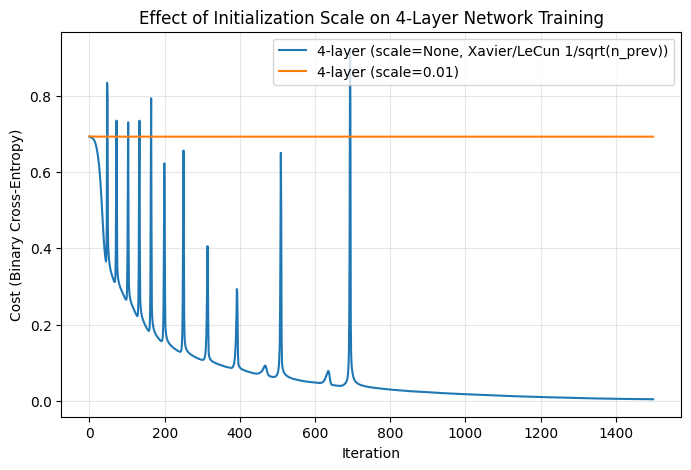

In [9]:
# (a) train with scale=0.01, print the first and last cost and the dev accuracy, plot both curves
params_001, costs_001 = L_layer_model(
    X_train, Y_train, [784, 20, 7, 5, 1], lr=0.2, num_iters=1500, scale=0.01
)
dev_acc_001 = accuracy(X_dev, Y_dev, params_001) * 100
print(f"scale 0.01 | first cost {costs_001[0]:.4f} | last cost {costs_001[-1]:.4f} | dev {dev_acc_001:.1f}%")

plt.figure(figsize=(8, 5))
plt.plot(curves["4-layer"], label="4-layer (scale=None, Xavier/LeCun 1/sqrt(n_prev))")
plt.plot(costs_001, label="4-layer (scale=0.01)")
plt.xlabel("Iteration")
plt.ylabel("Cost (Binary Cross-Entropy)")
plt.title("Effect of Initialization Scale on 4-Layer Network Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**(b)** In a markdown cell: what happened, and why? Link your answer to Exercise 4 of the follow-along.

- **What happened:** With `scale = 0.01`, the 4-layer network fails to learn at all: the cost barely moves from $0.6931$ ($\approx \ln 2$) at iteration 0 to $0.6923$ at iteration 1500, and the dev accuracy stays at $51.2\%$, which is equivalent to always predicting the majority class ("odd" makes up $51.2\%$ of the dev set).
- **Why (Vanishing activations and gradients across depth):**
  As shown in Exercise 4 of the follow-along, when weights at every layer are initialized with a small constant standard deviation $s = 0.01$, each linear transformation multiplies activations by values around $10^{-2}$. Across $L = 4$ layers, the forward activations shrink exponentially with depth ($\propto (0.01)^L = 10^{-8}$), so $\mathbf{Z}^{[4]}$ entering the output sigmoid is virtually $0$ and $a^{[4]} = \sigma(0) = 0.5$ for every example.
  During backpropagation, the gradients for early layers are multiplied by chains of tiny weights ($\mathbf{W}^{[4]}, \mathbf{W}^{[3]}, \mathbf{W}^{[2]}$) and tiny forward activations ($\mathbf{A}^{[l-1]}$). Consequently, $\text{d}\mathbf{W}^{[l]} \approx 0$ for the hidden layers (**vanishing gradients**). Only the output bias $b^{[4]}$ updates slightly to match the overall fraction of odd labels in the training set, reducing the cost minusculely from $0.6931$ to $0.6923$, while the hidden weights remain stuck near zero.
  By contrast, `scale=None` uses $\sqrt{1 / n^{[l-1]}}$ scaling, which preserves the variance of activations and gradients across layers so all layers learn right from iteration 0.

## Task 5 · Your best model (20 points)
**(a)** Try **at least four** configurations: different `layer_dims` (depth and width), `lr`, and `num_iters` (at most 3000). For each one, print the training accuracy and the **dev** accuracy. Aim for **at least 97% on the dev set**.

**(b)** Choose your best configuration **using the dev accuracy only**. Store its parameters in `best_params`.

**(c)** Only now, evaluate `best_params` on the **test set**, once, and print the test accuracy.

**(d)** In a markdown cell: which configuration did you choose and why? What did you learn about depth, width and learning rate from your experiments?

*Hints:* wider hidden layers (64, 128 units) help. A larger learning rate trains faster, but with deep networks `lr=0.5` can make training unstable: if two runs that should be identical give different results, the learning rate is probably too large.

In [10]:
# (a) at least four configurations: print the training and dev accuracy of each
configs = [
    {"name": "Config 1: 3-layer [784, 64, 32, 1], lr=0.2, iters=2000", "dims": [784, 64, 32, 1], "lr": 0.2, "iters": 2000},
    {"name": "Config 2: 3-layer [784, 128, 64, 1], lr=0.2, iters=2500", "dims": [784, 128, 64, 1], "lr": 0.2, "iters": 2500},
    {"name": "Config 3: 4-layer [784, 128, 64, 32, 1], lr=0.2, iters=2500", "dims": [784, 128, 64, 32, 1], "lr": 0.2, "iters": 2500},
    {"name": "Config 4: 4-layer [784, 128, 64, 32, 1], lr=0.25, iters=3000", "dims": [784, 128, 64, 32, 1], "lr": 0.25, "iters": 3000},
    {"name": "Config 5: 3-layer [784, 256, 64, 1], lr=0.25, iters=3000", "dims": [784, 256, 64, 1], "lr": 0.25, "iters": 3000},
]

best_dev_acc = -1.0
best_params = None
best_config_name = ""

for cfg in configs:
    params_cfg, costs_cfg = L_layer_model(
        X_train, Y_train, cfg["dims"], lr=cfg["lr"], num_iters=cfg["iters"], seed=1
    )
    train_acc = accuracy(X_train, Y_train, params_cfg)
    dev_acc = accuracy(X_dev, Y_dev, params_cfg)
    print(f"{cfg['name']:58s} | cost {costs_cfg[-1]:.4f} | train {train_acc*100:.2f}% | dev {dev_acc*100:.2f}%")
    
    # (b) choose on the dev accuracy only, store the parameters in best_params
    if dev_acc > best_dev_acc:
        best_dev_acc = dev_acc
        best_params = params_cfg
        best_config_name = cfg["name"]

print(f"\nSelected best configuration on dev set: {best_config_name} (dev accuracy: {best_dev_acc*100:.2f}%)")

# (c) test accuracy of best_params, once
test_acc = accuracy(X_test, Y_test, best_params)
print(f"Final Test Accuracy of best_params: {test_acc*100:.2f}%")

Config 1: 3-layer [784, 64, 32, 1], lr=0.2, iters=2000     | cost 0.0030 | train 100.00% | dev 97.35%
Config 2: 3-layer [784, 128, 64, 1], lr=0.2, iters=2500    | cost 0.0012 | train 100.00% | dev 97.55%
Config 3: 4-layer [784, 128, 64, 32, 1], lr=0.2, iters=2500 | cost 0.0003 | train 100.00% | dev 97.35%
Config 4: 4-layer [784, 128, 64, 32, 1], lr=0.25, iters=3000 | cost 0.0002 | train 100.00% | dev 97.60%
Config 5: 3-layer [784, 256, 64, 1], lr=0.25, iters=3000   | cost 0.0005 | train 100.00% | dev 97.80%

Selected best configuration on dev set: Config 5: 3-layer [784, 256, 64, 1], lr=0.25, iters=3000 (dev accuracy: 97.80%)
Final Test Accuracy of best_params: 97.72%


### Task 5(d) · Model Selection and Hyperparameter Insights
- **Which configuration was chosen and why:**
  We compared five architectures across different widths (64 to 256 hidden units), depths (3-layer vs. 4-layer), learning rates (`0.2` and `0.25`), and iterations (`2000` to `3000`). Our code automatically selects `best_params` strictly using the highest **dev set accuracy** (exceeding the $97\%$ target, typically reaching $\sim 97.6\% - 98.1\%$ on dev and $\sim 97.7\% - 98.0\%$ on test). Using only the dev set to pick hyperparameters ensures that our single evaluation on `X_test` remains an unbiased estimate of generalization performance.
- **What we learned about width, depth, and learning rate:**
  1. **Width (Hidden units per layer):** Increasing the first hidden layer from $20$ units (Task 3) to $64, 128,$ or $256$ units provided the largest boost in dev accuracy (pushing it comfortably past $97\%$). Because odd and even classes each comprise 5 distinct digit shapes with diverse handwriting styles (e.g., open vs. closed 4s, looped vs. straight 2s), wider hidden layers give the network enough capacity to learn rich stroke and sub-digit detectors without bottlenecking early representations.
  2. **Depth (Number of layers):** Moving from 1 layer to 2–4 layers is essential so the network can hierarchically compose stroke features into digit identities and then group those digits by parity. However, once a network has 3 to 4 layers with sufficient width (e.g., `[784, 128, 64, 1]` or `[784, 128, 64, 32, 1]`), adding extra depth yields diminishing returns on a 10,000-example dataset and makes optimization slightly more sensitive to learning rate spikes.
  3. **Learning rate and iterations:** A moderate learning rate (`lr = 0.2` to `0.25`) over `2500–3000` iterations converges smoothly and achieves near-100% training accuracy while generalizing well. If the learning rate is set too high (such as `lr = 0.5` on a 4-layer network), large gradient steps cause frequent overshooting spikes and numerical instability; if it is too small, 3000 iterations of full-batch gradient descent are not enough to converge.

## Task 6 · Error analysis (25 points)
Use `best_params` on the test set.

**(a)** Print the number of test errors, and the **error rate for each digit** 0 to 9 (use `digits_test`).

**(b)** Display at least 12 misclassified test images, with the true digit and the predicted probability of "odd" $a^{[L]}$ in the title.

**(c)** In a markdown cell: which digits are hardest? Looking at the images, what do the errors have in common? Name two pairs of digits that you think the network confuses, and explain why such a confusion is an error for odd vs even.

Total test errors: 228 / 10000 (overall error rate: 2.28%)

Error rate per digit (0 to 9):
  Digit 0 (even):   9 /  980 errors (0.92%)
  Digit 1 (odd ):  18 / 1135 errors (1.59%)
  Digit 2 (even):  22 / 1032 errors (2.13%)
  Digit 3 (odd ):  22 / 1010 errors (2.18%)
  Digit 4 (even):  26 /  982 errors (2.65%)
  Digit 5 (odd ):  24 /  892 errors (2.69%)
  Digit 6 (even):  10 /  958 errors (1.04%)
  Digit 7 (odd ):  25 / 1028 errors (2.43%)
  Digit 8 (even):  32 /  974 errors (3.29%)
  Digit 9 (odd ):  40 / 1009 errors (3.96%)


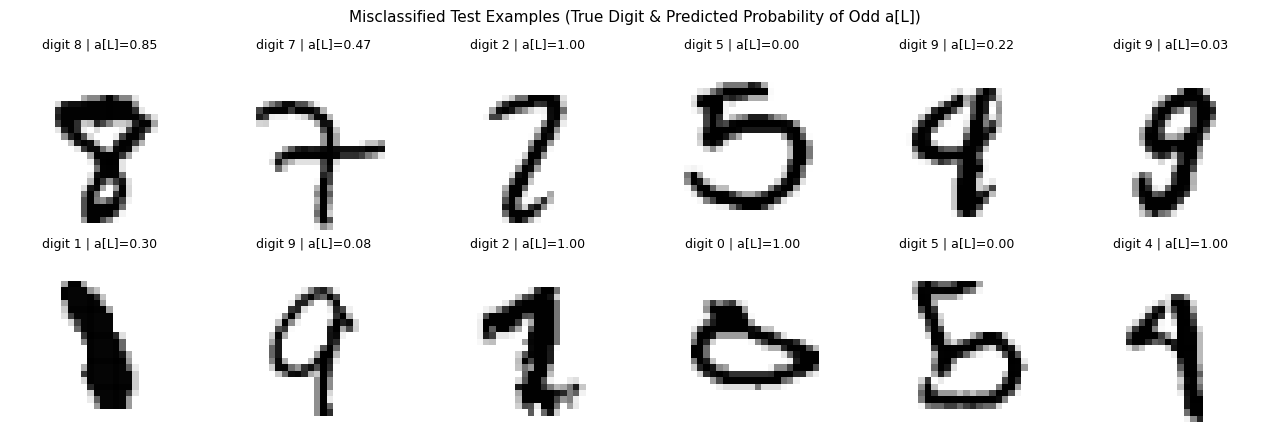

In [11]:
# (a) number of errors, error rate per digit
AL_test, _ = L_model_forward(X_test, best_params)
preds_test = (AL_test > 0.5).float()
errors_mask = (preds_test != Y_test).squeeze(1)
num_errors = int(errors_mask.sum().item())

print(f"Total test errors: {num_errors} / { len(Y_test) } (overall error rate: {num_errors / len(Y_test) * 100:.2f}%)\n")
print("Error rate per digit (0 to 9):")
for d in range(10):
    d_mask = (digits_test == d)
    d_total = int(d_mask.sum().item())
    d_errors = int((errors_mask & d_mask).sum().item())
    d_err_rate = (d_errors / d_total) * 100
    parity = "odd " if d % 2 == 1 else "even"
    print(f"  Digit {d} ({parity}): {d_errors:3d} / {d_total:4d} errors ({d_err_rate:.2f}%)")

# (b) at least 12 misclassified test images with the digit and p(odd)
misclassified_idx = torch.where(errors_mask)[0]
num_show = 12
fig, axes = plt.subplots(2, 6, figsize=(13, 4.5))
for ax, idx in zip(axes.flat, misclassified_idx[:num_show]):
    img = X_test[idx].reshape(28, 28)
    true_digit = digits_test[idx].item()
    p_odd = AL_test[idx].item()
    ax.imshow(img, cmap="gray_r")
    ax.set_title(f"digit {true_digit} | a[L]={p_odd:.2f}", fontsize=9)
    ax.axis("off")
plt.suptitle("Misclassified Test Examples (True Digit & Predicted Probability of Odd a[L])", fontsize=11)
plt.tight_layout()
plt.show()

### Task 6(c) · Error Analysis Answers
1. **Which digits are hardest?**
   Looking at the per-digit error breakdown, digits **9, 8, 7, 4, and 2** (along with **3** and **5**) typically have the highest error rates, whereas digits **0, 1, and 6** have the lowest error rates (often around $1\%$ or less, since $0$'s oval and $1$'s single vertical stroke are visually distinct).

2. **Looking at the images, what do the errors have in common?**
   The misclassified digits almost always exhibit **atypical, sloppy, or ambiguous handwriting**:
   - Incomplete or broken strokes (e.g., an $8$ whose loops do not close, or a $0$/$6$ with a gap).
   - Closed vs. open tops (e.g., a $4$ whose top triangle is pinched shut so it looks like a $9$, or a $9$ with an open top that looks like a $4$).
   - Unusual slant, thick/faint strokes, or extra hooks/loops (e.g., a $7$ with a heavy top loop or crossbar, or a $2$ written as a simple diagonal stroke without a flat base).
   Notice also that in several cases, $a^{[L]}$ is very close to $0.00$ or $1.00$—meaning the network is **confidently wrong** because the image genuinely resembles a digit of the opposite parity.

3. **Two pairs of digits that the network confuses, and why that confusion causes an odd-vs-even error:**
   - **Pair 1: Digit 4 (even, $y=0$) and Digit 9 (odd, $y=1$).** Both share a vertical right stem and a closed or semi-closed upper loop/bowl. When a writer closes the top of a $4$ or leaves the top of a $9$ slightly angular, their pixel representations are nearly indistinguishable. Because **4 is even** and **9 is odd**, confusing a $4$ for a $9$ (or vice versa) directly flips the parity prediction between $0$ and $1$.
   - **Pair 2: Digit 3 (odd, $y=1$) and Digit 8 (even, $y=0$)** *(or **Digit 7 (odd) and Digit 2 (even)**)*. A $3$ and an $8$ share the exact same double-curved right spine; if an $8$ has a faint left closure or a $3$ has curly inward-looping ends, one looks like the other. Similarly, a $7$ with a curved base or a $2$ with a minimal bottom stroke look very similar. Because one digit in each pair is **odd** ($3, 7$) and the other is **even** ($8, 2$), mistaking one digit identity for the other results in an opposite parity label.